## Exercises
## 练习

1. Why is the second derivative much more expensive to compute than the first derivative?
   为什么二阶导数的计算成本比一阶导数高得多？

2. After running the function for backpropagation, immediately run it again and see what happens. Investigate.
   在运行反向传播函数后，立即再次运行它并观察会发生什么。请进行调查分析。

3. In the control flow example where we calculate the derivative of `d` with respect to `a`, what would happen if we changed the variable `a` to a random vector or a matrix? At this point, the result of the calculation `f(a)` is no longer a scalar. What happens to the result? How do we analyze this?
   在我们计算 `d` 关于 `a` 的导数的控制流示例中，如果将变量 `a` 更改为随机向量或矩阵会发生什么？此时，`f(a)` 的计算结果不再是标量。结果会怎样变化？我们该如何分析这种情况？

4. Let $f(x) = \sin(x)$. Plot the graph of $f$ and of its derivative $f'$. Do not exploit the fact that $f'(x) = \cos(x)$ but rather use automatic differentiation to get the result.
   设 $f(x) = \sin(x)$。绘制 $f$ 及其导数 $f'$ 的图像。不要利用 $f'(x) = \cos(x)$ 这一已知事实，而是使用自动微分来获取结果。

5. Let $f(x) = ((\log x^2) \cdot \sin x) + x^{-1}$. Write out a dependency graph tracing results from $x$ to $f(x)$.
   设 $f(x) = ((\log x^2) \cdot \sin x) + x^{-1}$。写出一个从 $x$ 到 $f(x)$ 追踪结果的依赖图。

6. Use the chain rule to compute the derivative $\frac{df}{dx}$ of the aforementioned function, placing each term on the dependency graph that you constructed previously.
   使用链式法则计算上述函数的导数 $\frac{df}{dx}$，并将每一项标注在你之前构建的依赖图上。

7. Given the graph and the intermediate derivative results, you have a number of options when computing the gradient. Evaluate the result once starting from $x$ to $f$ and once from $f$ tracing back to $x$. The path from $x$ to $f$ is commonly known as *forward differentiation*, whereas the path from $f$ to $x$ is known as backward differentiation.
   给定该图和中间导数结果，你在计算梯度时有多种选择。分别尝试一次从 $x$ 到 $f$ 的计算和一次从 $f$ 回溯到 $x$ 的计算。从 $x$ 到 $f$ 的路径通常被称为*前向微分*，而从 $f$ 到 $x$ 的路径被称为反向微分。

8. When might you want to use forward, and when backward, differentiation? Hint: consider the amount of intermediate data needed, the ability to parallelize steps, and the size of matrices and vectors involved.
   什么时候应该使用前向微分，什么时候应该使用反向微分？提示：考虑所需的中间数据量、步骤并行化的能力以及所涉及的矩阵和向量的大小。

In [ ]:
import torch
from matplotlib_inline import backend_inline
from d2l import torch as d2l

In [ ]:
# 2.
x = torch.arange(4.0)
# Can also create x = torch.arange(4.0, requires_grad=True)
x.requires_grad_(True)
x.grad  # The gradient is None by default

In [ ]:
def y(x):
    return x[0]*x[0] + 4 *(x[1]**2) - x[2] * 4 + x[3]  
y(x)

In [ ]:
# x.grad.zero_()
y(x).backward()
x.grad

In [68]:
# 4.
def f(x):
    return torch.sin(x)

X = torch.linspace(-2 * torch.pi, 2 * torch.pi, 1000)

In [73]:
Y = []
grad = []
for x in X:
    x.requires_grad_(True)
    y = f(x)
    y.backward()
    Y.append(y)
    grad.append(x.grad)

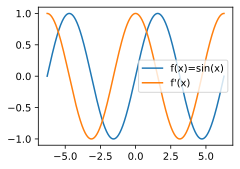

In [74]:
import matplotlib.pyplot as plt

Y = torch.stack(Y)
grad = torch.stack(grad)

plt.plot(X.detach().numpy(), Y.detach().numpy(), label='f(x)=sin(x)')
plt.plot(X.detach().numpy(), grad.detach().numpy(), label="f'(x)")

plt.legend()
plt.show()